In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
uploaded = files.upload()

image_name = list(uploaded.keys())[0]

img = cv2.imread(image_name)

if img is None:
    raise ValueError("Image could not be loaded!")

Saving Sunflower.webp to Sunflower.webp


In [3]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [4]:
laplacian = cv2.Laplacian(
    gray, cv2.CV_16S, ksize=3
)

laplacian_output = cv2.convertScaleAbs(laplacian)

In [5]:
laplacian_kernel = np.array([
    [0, -1, 0],
    [-1, 4, -1],
    [0, -1, 0]
], dtype=np.float32)

laplacian_response = cv2.filter2D(
    gray, cv2.CV_32F, laplacian_kernel
)

enhanced_laplacian = np.clip(
    gray.astype(np.float32) + laplacian_response,
    0, 255
).astype(np.uint8)

In [6]:
A = 1.5

blurred = cv2.GaussianBlur(
    gray, (5, 5), 0
)

high_boost = cv2.addWeighted(
    gray, A, blurred, -1.0, 0
)

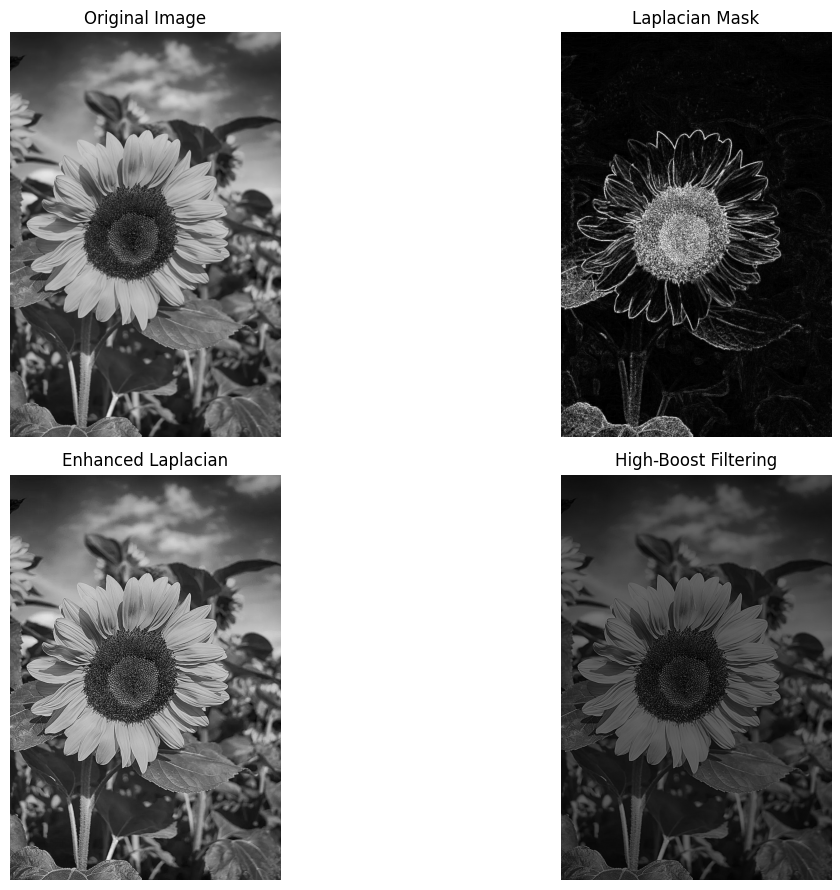

In [7]:
images = [
    ("Original Image", gray),
    ("Laplacian Mask", laplacian_output),
    ("Enhanced Laplacian", enhanced_laplacian),
    ("High-Boost Filtering", high_boost)
]

plt.figure(figsize=(14, 9))

for i, (title, image) in enumerate(images):
    plt.subplot(2, 2, i + 1)
    plt.imshow(image, cmap='gray')
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
cv2.imwrite("Laplacian_Output.png", laplacian_output)

cv2.imwrite("Enhanced_Laplacian.png", enhanced_laplacian)

cv2.imwrite("High_Boost_Output.png", high_boost)

print("Laplacian and High-Boost Operations Completed Successfully!")

Laplacian and High-Boost Operations Completed Successfully!
